---
title: "Practice Activity 13-1: Multiclass Classification"
author: "Shiqi Wu"
format:
  html:
    embed-resources: true
    code-overflow: wrap
---

# Multiclass Classification

Our dataset consists of clinical data from patients who entered the hospital complaining of chest pain ("angina") during exercise.  The information collected includes:

* `age` : Age of the patient

* `sex` : Sex of the patient

* `cp` : Chest Pain type

    + Value 0: asymptomatic
    + Value 1: typical angina
    + Value 2: atypical angina
    + Value 3: non-anginal pain
   
    
* `trtbps` : resting blood pressure (in mm Hg)

* `chol` : cholesterol in mg/dl fetched via BMI sensor

* `restecg` : resting electrocardiographic results

    + Value 0: normal
    + Value 1: having ST-T wave abnormality (T wave inversions and/or ST elevation or depression of > 0.05 mV)
    + Value 2: showing probable or definite left ventricular hypertrophy by Estes' criteria

* `thalach` : maximum heart rate achieved during exercise

* `output` : the doctor's diagnosis of whether the patient is at risk for a heart attack
    + 0 = not at risk of heart attack
    + 1 = at risk of heart attack

In [1]:
## library imports here
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from plotnine import *

First we'll create binary variables for each class.

In [2]:
ha = pd.read_csv("https://www.dropbox.com/s/aohbr6yb9ifmc8w/heart_attack.csv?dl=1")

ha["cp_is_3"] = ((ha["cp"] == 3) * 1)
ha["cp_is_2"] = ((ha["cp"] == 2) * 1)
ha["cp_is_1"] = ((ha["cp"] == 1) * 1)
ha["cp_is_0"] = ((ha["cp"] == 0) * 1)

# strings for the purposes of plotting
ha["cp"] = ha["cp"].astype("str")
ha

,age,sex,cp,trtbps,chol,restecg,thalach,output,cp_is_3,cp_is_2,cp_is_1,cp_is_0
0,63,1,3,145,233,0,150,1,1,0,0,0
1,37,1,2,130,250,1,187,1,0,1,0,0
2,56,1,1,120,236,1,178,1,0,0,1,0
3,57,0,0,120,354,1,163,1,0,0,0,1
4,57,1,0,140,192,1,148,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
268,59,1,0,164,176,0,90,0,0,0,0,1
269,57,0,0,140,241,1,123,0,0,0,0,1
270,45,1,3,110,264,1,132,0,1,0,0,0
271,68,1,0,144,193,1,141,0,0,0,0,1


The target is `cp` which has 4 categories. How common is each category?

In [3]:
ha["cp"].value_counts().sort_index()

cp
0    128
1     44
2     81
3     20
Name: count, dtype: int64

Let's consider as predictors: `trtbps`, `chol`, `age`.

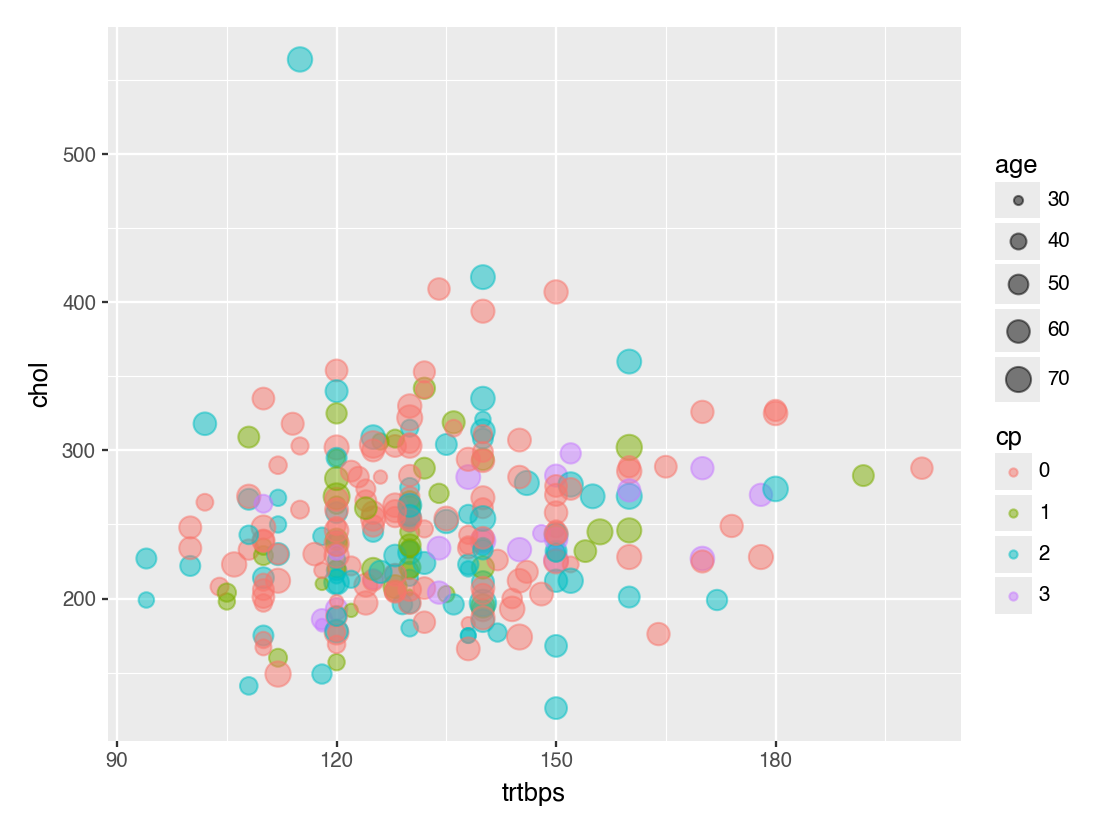

In [4]:
(ggplot(ha, aes(x="trtbps", y="chol", size = "age", color="cp"))
+ geom_point(alpha = 0.5))

## Q1: A Natural Multiclass Model: k-nearest neighbors

Fit a multiclass 10-nearest neighbors model. Output the predicted class probabilities and plot the predicted classes for the training data. Estimate the test:

- accuracy
- macro precision, recall, and F1 scores
- precision, recall, and F1 score for each class. You will likely get some weird values; can you explain why?


In [5]:
X = ha[["trtbps", "chol", "age"]]
y = ha["cp"]

knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=10))
])

knn_model.fit(X, y)

knn_probabilities = pd.DataFrame(
    knn_model.predict_proba(X),
    index=ha.index,
    columns=[f"P(cp = {label})" for label in knn_model.classes_]
)

knn_probabilities

,P(cp = 0),P(cp = 1),P(cp = 2),P(cp = 3)
0,0.5,0.1,0.1,0.3
1,0.2,0.1,0.6,0.1
2,0.2,0.5,0.3,0.0
3,0.7,0.2,0.1,0.0
4,0.6,0.1,0.2,0.1
...,...,...,...,...
268,0.3,0.1,0.5,0.1
269,0.5,0.2,0.2,0.1
270,0.4,0.1,0.4,0.1
271,0.7,0.1,0.1,0.1


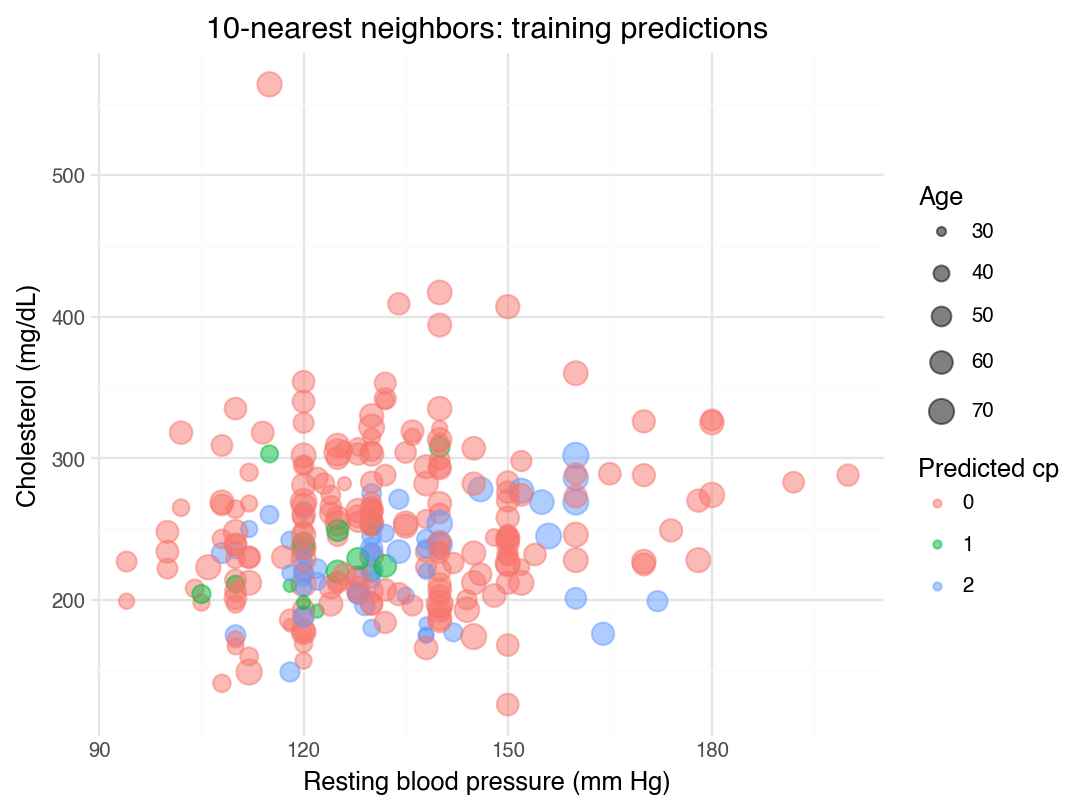

In [6]:
knn_plot_data = ha.assign(predicted_cp=knn_model.predict(X))

(
    ggplot(
        knn_plot_data,
        aes(x="trtbps", y="chol", size="age", color="predicted_cp")
    )
    + geom_point(alpha=0.5)
    + labs(
        x="Resting blood pressure (mm Hg)",
        y="Cholesterol (mg/dL)",
        size="Age",
        color="Predicted cp",
        title="10-nearest neighbors: training predictions"
    )
    + theme_minimal()
)

In [7]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import classification_report

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

knn_cv_predictions = cross_val_predict(
    knn_model,
    X,
    y,
    cv=cv
)

print(
    classification_report(
        y,
        knn_cv_predictions,
        labels=knn_model.classes_,
        digits=3,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0      0.483     0.781     0.597       128
           1      0.167     0.045     0.071        44
           2      0.192     0.123     0.150        81
           3      0.000     0.000     0.000        20

    accuracy                          0.410       273
   macro avg      0.211     0.238     0.205       273
weighted avg      0.310     0.410     0.336       273



**Answer:** Using five-fold stratified cross-validation, the estimated test accuracy was 0.410. Macro precision was 0.211, macro recall was 0.238, and macro F1 was 0.205.

The model performed best on class 0, with an F1 score of 0.597. Precision, recall, and F1 for class 3 were all zero because no class 3 observations were correctly classified during cross-validation. Class 3 has only 20 observations, so it can easily be outvoted by other classes among the 10 nearest neighbors. Overlap between the classes in these predictors may also contribute to the low scores.

## Q2:  OvR for Class 3



Fit a logistic regression model for predicting Class 3. Output the predicted class probabilities (Class 3 or not) and plot the predicted classes (Class 3 or not) for the training data. Estimate the test:

- precision, recall, and F1 score for class 3

In [8]:
y_class3 = ha["cp_is_3"]

ovr3_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=1000))
])

ovr3_model.fit(X, y_class3)

class3_probabilities = pd.DataFrame(
    ovr3_model.predict_proba(X),
    index=ha.index,
    columns=["P(not class 3)", "P(class 3)"]
)

class3_probabilities

,P(not class 3),P(class 3)
0,0.901104,0.098896
1,0.941224,0.058776
2,0.951037,0.048963
3,0.971022,0.028978
4,0.898105,0.101895
...,...,...
268,0.801764,0.198236
269,0.917096,0.082904
270,0.967963,0.032037
271,0.885371,0.114629


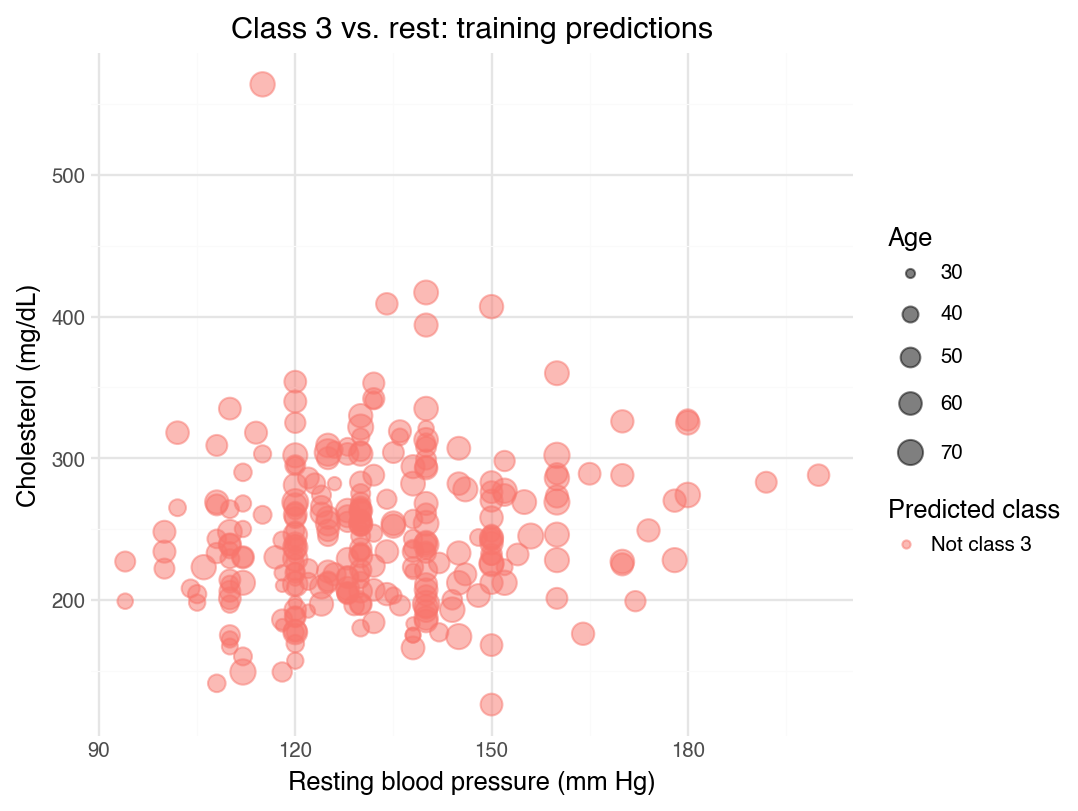

In [10]:
class3_plot_data = ha.assign(predicted_class3=ovr3_model.predict(X))

class3_plot_data["predicted_class3"] = (
    class3_plot_data["predicted_class3"]
    .map({0: "Not class 3", 1: "Class 3"})
)

(
    ggplot(
        class3_plot_data,
        aes(x="trtbps", y="chol", size="age", color="predicted_class3")
    )
    + geom_point(alpha=0.5)
    + labs(
        x="Resting blood pressure (mm Hg)",
        y="Cholesterol (mg/dL)",
        size="Age",
        color="Predicted class",
        title="Class 3 vs. rest: training predictions"
    )
    + theme_minimal()
)

In [11]:
from sklearn.metrics import precision_score, recall_score, f1_score

class3_cv_predictions = cross_val_predict(
    ovr3_model,
    X,
    y_class3,
    cv=cv
)

class3_cv_scores = pd.Series({
    "Precision": precision_score(
        y_class3, class3_cv_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_class3, class3_cv_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_class3, class3_cv_predictions, zero_division=0
    )
}, name="Class 3")

class3_cv_scores

Precision    0.0
Recall       0.0
F1           0.0
Name: Class 3, dtype: float64

**Answer:** Using five-fold stratified cross-validation, the estimated precision, recall, and F1 score for class 3 were all 0.000. At the default 0.5 cutoff, the model predicted every validation observation as not class 3, so it missed all 20 class 3 observations. Precision was undefined because there were no positive predictions, and `zero_division=0` reported it as zero. The training prediction plot also shows all observations classified as not class 3.

## Q3: OvR - Other classes.

Repeat Q2 for each of the other three `cp` categories.  Which category was the OvR approach best at distinguishing?

In [13]:
from IPython.display import display

ovr_models = {}
ovr_probabilities = {}

for class_label in [0, 1, 2]:
    target = ha[f"cp_is_{class_label}"]

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(max_iter=1000))
    ])

    model.fit(X, target)

    ovr_models[class_label] = model
    ovr_probabilities[class_label] = pd.DataFrame(
        model.predict_proba(X),
        index=ha.index,
        columns=[
            f"P(not class {class_label})",
            f"P(class {class_label})"
        ]
    )

    print(f"Class {class_label} vs. rest")
    display(ovr_probabilities[class_label])

Class 0 vs. rest


,P(not class 0),P(class 0)
0,0.478092,0.521908
1,0.678292,0.321708
2,0.504099,0.495901
3,0.443054,0.556946
4,0.543651,0.456349
...,...,...
268,0.567364,0.432636
269,0.522096,0.477904
270,0.577090,0.422910
271,0.448706,0.551294


Class 1 vs. rest


,P(not class 1),P(class 1)
0,0.894867,0.105133
1,0.734949,0.265051
2,0.845941,0.154059
3,0.820938,0.179062
4,0.876054,0.123946
...,...,...
268,0.902109,0.097891
269,0.865861,0.134139
270,0.762384,0.237616
271,0.916776,0.083224


Class 2 vs. rest


,P(not class 2),P(class 2)
0,0.731442,0.268558
1,0.638588,0.361412
2,0.706497,0.293503
3,0.753821,0.246179
4,0.693586,0.306414
...,...,...
268,0.695694,0.304306
269,0.712897,0.287103
270,0.675674,0.324326
271,0.734003,0.265997


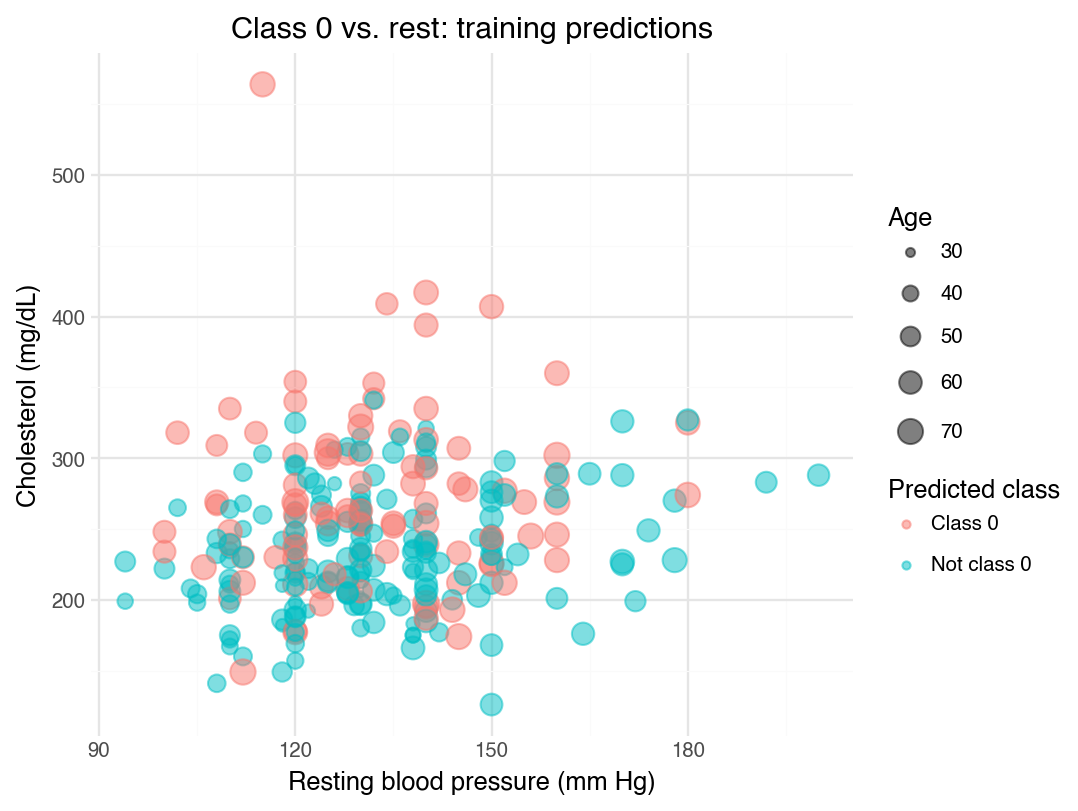

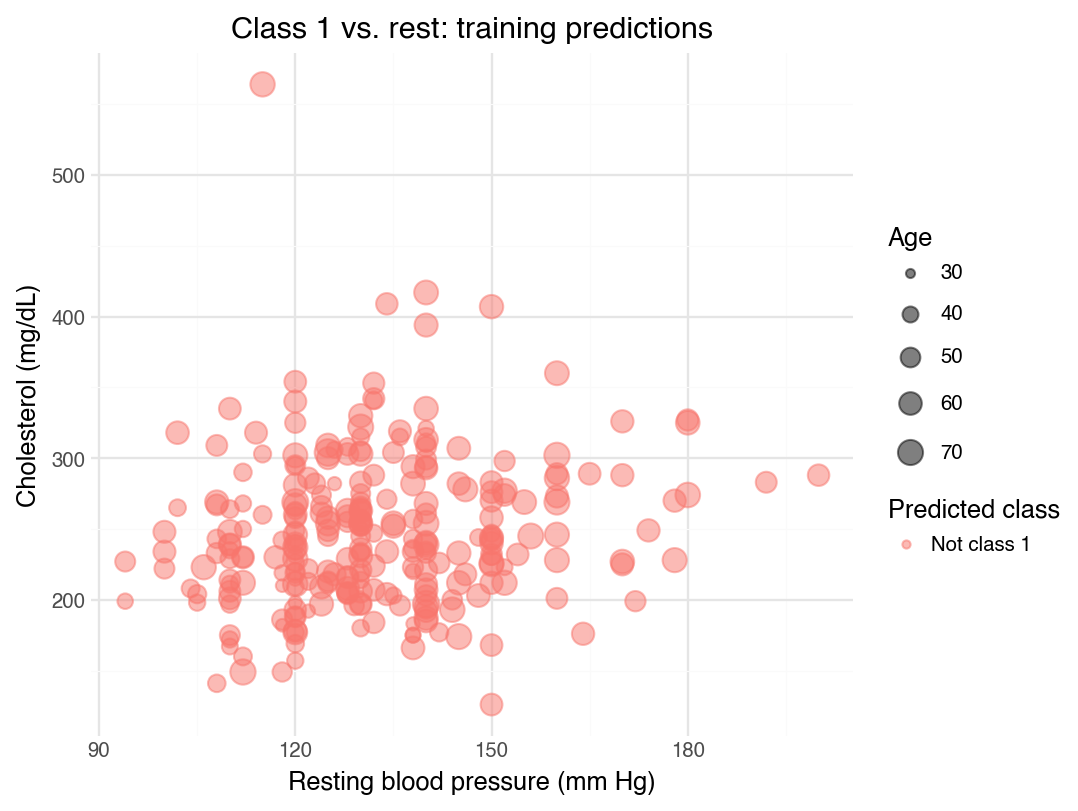

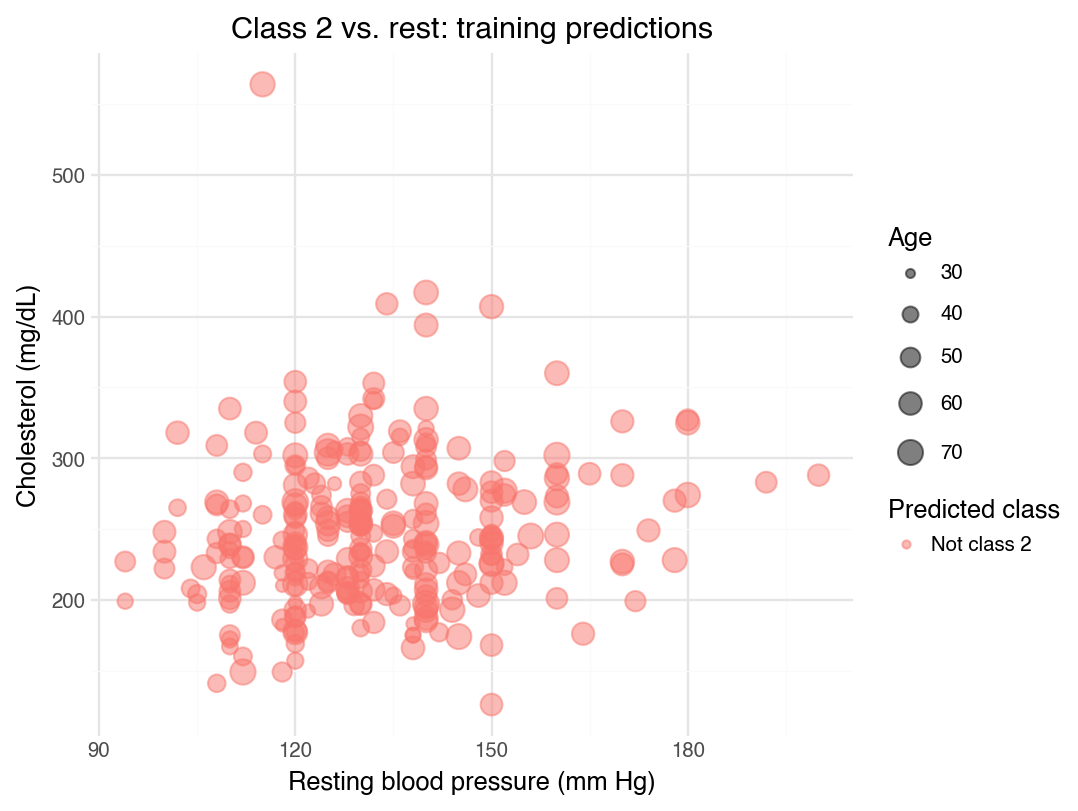

In [14]:
for class_label in [0, 1, 2]:
    ovr_plot_data = ha.assign(
        predicted_class=ovr_models[class_label].predict(X)
    )

    ovr_plot_data["predicted_class"] = (
        ovr_plot_data["predicted_class"].map({
            0: f"Not class {class_label}",
            1: f"Class {class_label}"
        })
    )

    ovr_plot = (
        ggplot(
            ovr_plot_data,
            aes(x="trtbps", y="chol", size="age", color="predicted_class")
        )
        + geom_point(alpha=0.5)
        + labs(
            x="Resting blood pressure (mm Hg)",
            y="Cholesterol (mg/dL)",
            size="Age",
            color="Predicted class",
            title=f"Class {class_label} vs. rest: training predictions"
        )
        + theme_minimal()
    )

    display(ovr_plot)

In [16]:
ovr_cv_results = []

for class_label in [0, 1, 2]:
    target = ha[f"cp_is_{class_label}"]

    predictions = cross_val_predict(
        ovr_models[class_label],
        X,
        target,
        cv=cv
    )

    ovr_cv_results.append({
        "Class": class_label,
        "Precision": precision_score(target, predictions, zero_division=0),
        "Recall": recall_score(target, predictions, zero_division=0),
        "F1": f1_score(target, predictions, zero_division=0)
    })

ovr_cv_scores = pd.DataFrame(ovr_cv_results).set_index("Class")
ovr_cv_scores.loc[3] = class3_cv_scores

ovr_cv_scores.round(3)

,Precision,Recall,F1
Class,,,
0,0.554,0.438,0.489
1,0.000,0.000,0.000
2,0.000,0.000,0.000
3,0.000,0.000,0.000


**Answer:** OvR worked best for class 0 under these settings. Its estimated test precision was 0.554, recall was 0.438, and F1 was 0.489, the highest among the four classes. For classes 1, 2, and 3, the models made no positive predictions during cross-validation at the default 0.5 cutoff, so their F1 scores were all 0.000. Even for class 0, recall was below 0.5, meaning the model missed more than half of the actual class 0 observations.

## Q4: OvO

Reduce your dataset to only the `0` and `1` types of chest pain.

Then, fit a Logistic Regression to predict between the two groups, and estimate the ROC-AUC.  


In [17]:
from sklearn.model_selection import cross_val_score

ha_01 = ha.loc[ha["cp"].isin(["0", "1"])].copy()

X_01 = ha_01[["trtbps", "chol", "age"]]
y_01 = ha_01["cp"].astype(int)

ovo01_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=1000))
])

ovo01_model.fit(X_01, y_01)

auc_01_scores = cross_val_score(
    ovo01_model,
    X_01,
    y_01,
    cv=cv,
    scoring="roc_auc"
)

print(f"Mean cross-validated ROC-AUC: {auc_01_scores.mean():.3f}")

Mean cross-validated ROC-AUC: 0.628


**Answer:** I kept the 172 observations in classes 0 and 1 and fitted a logistic regression model using resting blood pressure, cholesterol, and age. The mean ROC-AUC from five-fold stratified cross-validation was 0.628. This suggests modest ability to distinguish class 1 from class 0.

## Q5: OvO

Repeat Q4 comparing category `0` to `2`, and again to compare category `0` to `3`.  Which pair was the OvO approach best at distinguishing?

In [18]:
ovo_cv_results = [
    {"Pair": "0 vs. 1", "ROC-AUC": auc_01_scores.mean()}
]

for class_label in ["2", "3"]:
    ha_pair = ha.loc[ha["cp"].isin(["0", class_label])].copy()

    X_pair = ha_pair[["trtbps", "chol", "age"]]
    y_pair = ha_pair[f"cp_is_{class_label}"]

    pair_model = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(max_iter=1000))
    ])

    pair_model.fit(X_pair, y_pair)

    pair_auc_scores = cross_val_score(
        pair_model,
        X_pair,
        y_pair,
        cv=cv,
        scoring="roc_auc"
    )

    ovo_cv_results.append({
        "Pair": f"0 vs. {class_label}",
        "ROC-AUC": pair_auc_scores.mean()
    })

ovo_cv_scores = pd.DataFrame(ovo_cv_results).set_index("Pair")

ovo_cv_scores.round(3)

,ROC-AUC
Pair,
0 vs. 1,0.628
0 vs. 2,0.578
0 vs. 3,0.601


**Answer:** The mean ROC-AUC from five-fold stratified cross-validation was 0.578 for classes 0 and 2, and 0.601 for classes 0 and 3. The comparison between classes 0 and 1 had the highest ROC-AUC at 0.628, so OvO was best at distinguishing these two classes under the current model settings.